# Visualize Next-State Extrapolation Scaling

This Visualize notebook loads the cache produced by `Generate-extrapolation-data.ipynb` and plots how normalized expected-value error for predicting the next quantized state scales with context length across the main numerical input families using Llama-3.2-3B, as presented in the appendix **Main Numerical Input Suite and Next-State Extrapolation**.


Load plotting dependencies.


In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb

CACHE_PATH = Path("cache/extrapolation_scaling_data.npz")
FIGURE_PATH = Path("figures/extrapolation_scaling_error.pdf")

# Quantization metadata in the generated cache
SCALING_QUANTIZED_STATE_MIN = 50
SCALING_QUANTIZED_STATE_MAX = 950
SCALING_ERROR_NORMALIZATION = float(SCALING_QUANTIZED_STATE_MAX - SCALING_QUANTIZED_STATE_MIN)

if not CACHE_PATH.exists():
    raise FileNotFoundError(
        f"Missing compact cache at {CACHE_PATH}. "
        "Run Generate-Extrapolation-Data.ipynb to create it."
    )


Define display labels and line styles shared by the figure.


In [2]:
SCALING_FIGSIZE = (6.4, 4.86)
SCALING_INLINE_DPI = 150
SCALING_FONT_SCALE = 1.15
SCALING_AXIS_LABEL_SIZE = 12.42
SCALING_TICK_LABEL_SIZE = 10.35
SCALING_ENDPOINT_LABEL_SIZE = 8.0 * SCALING_FONT_SCALE
SCALING_ENDPOINT_LABEL_DARKENING = 0.78
SCALING_REFERENCE_LABEL_SIZE = 10.0 * SCALING_FONT_SCALE
SCALING_BAND_ALPHA = 0.045

def _scaling_display_name(data_name):
    display_names = {
        "Constant sampled": "Constant sampled",
        "Logistic r=3.2": "Logistic r=3.2 (period 2)",
        "Logistic r=3.5": "Logistic r=3.5 (period 4)",
        "Logistic r=3.55": "Logistic r=3.55 (period 8)",
        "Logistic r=3.566": "Logistic r=3.566 (period 16)",
        "Logistic r=3.5692": "Logistic r=3.5692 (period 32)",
        "Logistic r=3.5698": "Logistic r=3.5698 (period 64)",
        "Logistic r=3.9": "Logistic r=3.9 (chaotic)",
        "Logistic r=4.0": "Logistic r=4.0 (chaotic)",
        "Lorenz": "Lorenz",
    }
    return display_names.get(data_name, data_name)

def _scaling_line_style(data_name, ensemble=True):
    if data_name in {"Constant 500", "Constant sampled"}:
        style = dict(color="#D8D7E6", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.2":
        style = dict(color="#C6D9F1", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.5":
        style = dict(color="#A9C8EA", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.55":
        style = dict(color="#83B2DC", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.566":
        style = dict(color="#5F98CA", linestyle="-", marker="o", linewidth=2.0)
    elif data_name == "Logistic r=3.5692":
        style = dict(color="#3E78B2", linestyle="-", marker="o", linewidth=2.2)
    elif data_name == "Logistic r=3.5698":
        style = dict(color="#24518A", linestyle="-", marker="o", linewidth=2.2)
    elif data_name == "Logistic r=3.9":
        style = dict(color="#E68169", linestyle="-.", marker="o", linewidth=2.4)
    elif data_name == "Logistic r=4.0":
        style = dict(color="#C8525E", linestyle="-.", marker="o", linewidth=2.4)
    elif data_name == "Lorenz":
        style = dict(color="#98334F", linestyle="-.", marker="o", linewidth=2.8)
    else:
        style = dict(color="#4C72B0", linestyle="-", marker="o", linewidth=2.0)

    if data_name == "Lorenz":
        style["zorder"] = 5
    elif data_name in {"Logistic r=3.9", "Logistic r=4.0"}:
        style["zorder"] = 4
    else:
        style["zorder"] = 2

    style["markersize"] = 4.0 if ensemble else 4.5
    return style


def _scaling_darken_color(color, factor=0.78):
    return tuple(factor * channel for channel in to_rgb(color))

def _scaling_endpoint_label_text(data_name):
    label_map = {
        "Constant sampled": "Constant",
        "Logistic r=3.2": "Period 2",
        "Logistic r=3.5": "Period 4",
        "Logistic r=3.55": "Period 8",
        "Logistic r=3.566": "Period 16",
        "Logistic r=3.5692": "Period 32",
        "Logistic r=3.5698": "Period 64",
        "Logistic r=3.9": "r=3.9",
        "Logistic r=4.0": "r=4.0",
        "Lorenz": "Lorenz",
    }
    return label_map.get(data_name)


def _scaling_endpoint_label_offset(data_name, ensemble=True):
    if not ensemble:
        return 0.0
    label_offsets = {
        "Logistic r=3.566": 0.10,
        "Logistic r=3.5": 0.04,
        "Logistic r=3.2": 0.07,
        "Logistic r=3.55": -0.08,
        "Logistic r=3.5692": -0.16,
        "Logistic r=3.5698": -0.30,
    }
    return label_offsets.get(data_name, 0.0)


def _add_endpoint_label(ax, x, y, label, color, y_offset=0.0, x_offset=10.0, fontsize=SCALING_ENDPOINT_LABEL_SIZE):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    if x.size == 0 or y.size == 0:
        return
    if not np.isfinite(x[-1]) or not np.isfinite(y[-1]):
        return

    label_y = float(y[-1]) * (10.0 ** float(y_offset))
    ax.text(
        float(x[-1]) + float(x_offset),
        label_y,
        str(label),
        color=color,
        fontsize=fontsize,
        ha="left",
        va="center",
        clip_on=False,
    )


def _format_scaling_axis(ax, ylabel):
    ax.set_xticks(np.arange(0, 2001, 400))
    ax.set_xlim(0, 2000)
    ax.set_xlabel("Context length (tokens)", fontsize=SCALING_AXIS_LABEL_SIZE)
    ax.set_ylabel(ylabel, fontsize=SCALING_AXIS_LABEL_SIZE)
    ax.tick_params(axis="both", which="major", labelsize=SCALING_TICK_LABEL_SIZE)
    ax.set_axisbelow(True)
    ax.grid(True, axis="y", alpha=0.18, linewidth=0.8)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)


Load the compact figure-reproduction cache.


In [3]:
# Load cached plotting data and verify its required fields
with np.load(CACHE_PATH, allow_pickle=False) as cached:
    required_fields = {
        "rep_id",
        "data_name",
        "seq_len",
        "normalized_abs_error",
        "data_order",
        "scaling_error_log_floor",
        "scaling_error_normalization",
        "quantized_state_min",
        "quantized_state_max",
    }
    missing_fields = sorted(required_fields.difference(cached.files))
    if missing_fields:
        raise ValueError(f"Compact cache is missing required fields: {missing_fields}.")

    scaling_ensemble_data_order = [str(x) for x in cached["data_order"].astype(str).tolist()]
    scaling_error_log_floor = float(np.asarray(cached["scaling_error_log_floor"]).item())
    cached_error_normalization = float(np.asarray(cached["scaling_error_normalization"]).item())
    cached_quantized_state_min = int(np.asarray(cached["quantized_state_min"]).item())
    cached_quantized_state_max = int(np.asarray(cached["quantized_state_max"]).item())
    scaling_extrapolation_df = pd.DataFrame(
        {
            "rep_id": cached["rep_id"].astype(int),
            "data_name": cached["data_name"].astype(str),
            "seq_len": cached["seq_len"].astype(int),
            "normalized_abs_error": cached["normalized_abs_error"].astype(float),
        }
    )

# Reject caches created with different quantization settings
if cached_quantized_state_min != SCALING_QUANTIZED_STATE_MIN:
    raise ValueError(
        f"Cache quantized_state_min={cached_quantized_state_min}, expected {SCALING_QUANTIZED_STATE_MIN}."
    )
if cached_quantized_state_max != SCALING_QUANTIZED_STATE_MAX:
    raise ValueError(
        f"Cache quantized_state_max={cached_quantized_state_max}, expected {SCALING_QUANTIZED_STATE_MAX}."
    )
if not np.isclose(cached_error_normalization, SCALING_ERROR_NORMALIZATION):
    raise ValueError(
        f"Cache scaling_error_normalization={cached_error_normalization:g}, "
        f"expected {SCALING_ERROR_NORMALIZATION:g}. Regenerate the cache with Generate-Extrapolation-Data.ipynb."
    )

# Convert token counts to state counts
scaling_extrapolation_df["ctx_len"] = scaling_extrapolation_df["seq_len"] // 2
scaling_extrapolation_df["context_percent"] = np.rint(
    scaling_extrapolation_df["ctx_len"] / (1000 - 1) * 100
).astype(int)
scaling_extrapolation_df["display_name"] = scaling_extrapolation_df["data_name"].map(_scaling_display_name)
scaling_extrapolation_df["data_name"] = pd.Categorical(
    scaling_extrapolation_df["data_name"],
    categories=scaling_ensemble_data_order,
    ordered=True,
)
scaling_extrapolation_df = scaling_extrapolation_df.sort_values(
    ["data_name", "rep_id", "seq_len"]
).reset_index(drop=True)
scaling_ensemble_R = int(scaling_extrapolation_df["rep_id"].nunique())


Plot normalized absolute error as geometric mean plus or minus log standard deviation across replicates.


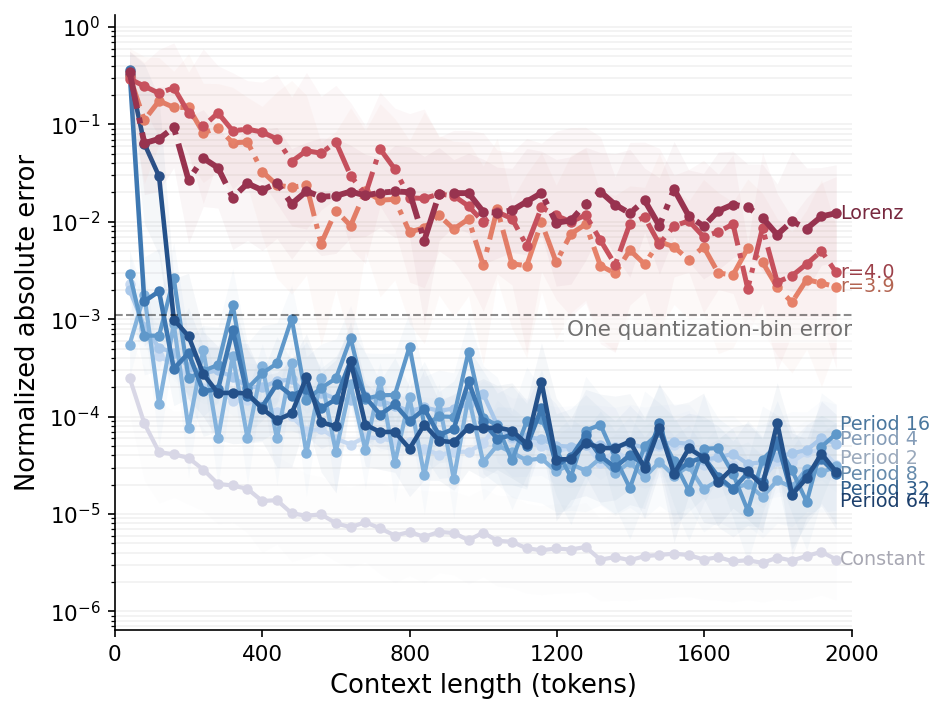

In [4]:
# Mark the normalized error corresponding to one quantization bin
scaling_quantization_error_scale = 1.0 / SCALING_ERROR_NORMALIZATION
scaling_quantization_error_label = "One quantization-bin error"


def _add_scaling_quantization_reference(ax):
    ax.axhline(
        scaling_quantization_error_scale,
        color="black",
        linestyle="--",
        linewidth=1.0,
        alpha=0.45,
        zorder=8.0,
    )
    x_right = ax.get_xlim()[1]
    ax.text(
        x_right,
        scaling_quantization_error_scale / 1.12,
        scaling_quantization_error_label,
        color="black",
        alpha=0.55,
        fontsize=SCALING_REFERENCE_LABEL_SIZE * 0.9,
        ha="right",
        va="top",
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.5, pad=1.5),
        zorder=8.5,
    )


# Floor zero-valued errors before taking logarithms
scaling_plot_source_df = scaling_extrapolation_df.copy()
scaling_plot_source_df["log_normalized_abs_error"] = np.log(
    np.maximum(
        scaling_plot_source_df["normalized_abs_error"].to_numpy(dtype=float),
        scaling_error_log_floor,
    )
)

# Summarize each curve by geometric mean and one log standard deviation
scaling_plot_df = (
    scaling_plot_source_df
    .groupby(["data_name", "display_name", "context_percent", "ctx_len", "seq_len"], observed=True)
    .agg(
        mean_normalized_abs_error=("normalized_abs_error", "mean"),
        std_normalized_abs_error=("normalized_abs_error", "std"),
        mean_log_normalized_abs_error=("log_normalized_abs_error", "mean"),
        std_log_normalized_abs_error=("log_normalized_abs_error", "std"),
    )
    .reset_index()
)
scaling_plot_df["std_normalized_abs_error"] = scaling_plot_df["std_normalized_abs_error"].fillna(0.0)
scaling_plot_df["std_log_normalized_abs_error"] = scaling_plot_df["std_log_normalized_abs_error"].fillna(0.0)
scaling_plot_df["data_name"] = pd.Categorical(
    scaling_plot_df["data_name"],
    categories=scaling_ensemble_data_order,
    ordered=True,
)
scaling_plot_df = scaling_plot_df.sort_values(["data_name", "seq_len"]).reset_index(drop=True)

fig, ax = plt.subplots(1, 1, figsize=SCALING_FIGSIZE, dpi=SCALING_INLINE_DPI)

# Draw curves and log-standard-deviation bands in the cached input order
endpoint_label_x_offset = 10.0
for data_name in scaling_ensemble_data_order:
    df_plot = scaling_plot_df[scaling_plot_df["data_name"] == data_name].sort_values("seq_len")
    if df_plot.empty:
        continue

    x = df_plot["seq_len"].to_numpy(dtype=float)
    y_log = df_plot["mean_log_normalized_abs_error"].to_numpy(dtype=float)
    y = np.exp(y_log)
    y_log_std = df_plot["std_log_normalized_abs_error"].to_numpy(dtype=float)
    style = _scaling_line_style(data_name, ensemble=True)

    ax.plot(x, y, **style)
    ax.fill_between(
        x,
        np.exp(y_log - y_log_std),
        np.exp(y_log + y_log_std),
        color=style["color"],
        alpha=SCALING_BAND_ALPHA,
        linewidth=0,
        zorder=max(style.get("zorder", 2) - 0.5, 0),
    )

    endpoint_label = _scaling_endpoint_label_text(data_name)
    if endpoint_label is not None:
        _add_endpoint_label(
            ax,
            x,
            y,
            endpoint_label,
            color=_scaling_darken_color(style["color"], SCALING_ENDPOINT_LABEL_DARKENING),
            y_offset=_scaling_endpoint_label_offset(data_name, ensemble=True),
            x_offset=endpoint_label_x_offset,
            fontsize=SCALING_ENDPOINT_LABEL_SIZE,
        )

_format_scaling_axis(ax, "Normalized absolute error")
ax.set_yscale("log", nonpositive="clip")
_add_scaling_quantization_reference(ax)
ax.grid(True, which="both", axis="y", alpha=0.18, linewidth=0.8)

plt.tight_layout()
FIGURE_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURE_PATH, format="pdf", bbox_inches="tight", pad_inches=0.02)
plt.show()
